<a href="https://colab.research.google.com/github/mountain-168/bai_2hoiquytuyentinh/blob/main/Tu%E1%BA%A7n_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Cấu hình hiển thị biểu đồ
%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 5)

=== THỐNG KÊ 3 ĐẶC TRƯNG SELECTION ===


,Feature,Mean,Std,Skewness,IQR Outliers,Correlation (r)
0,bmi,-2.245564e-16,0.047619,0.598148,3,0.586450
1,bp,-4.797570e-17,0.047619,0.290658,0,0.441482
2,s5,9.293722e-17,0.047619,0.291754,4,0.565883


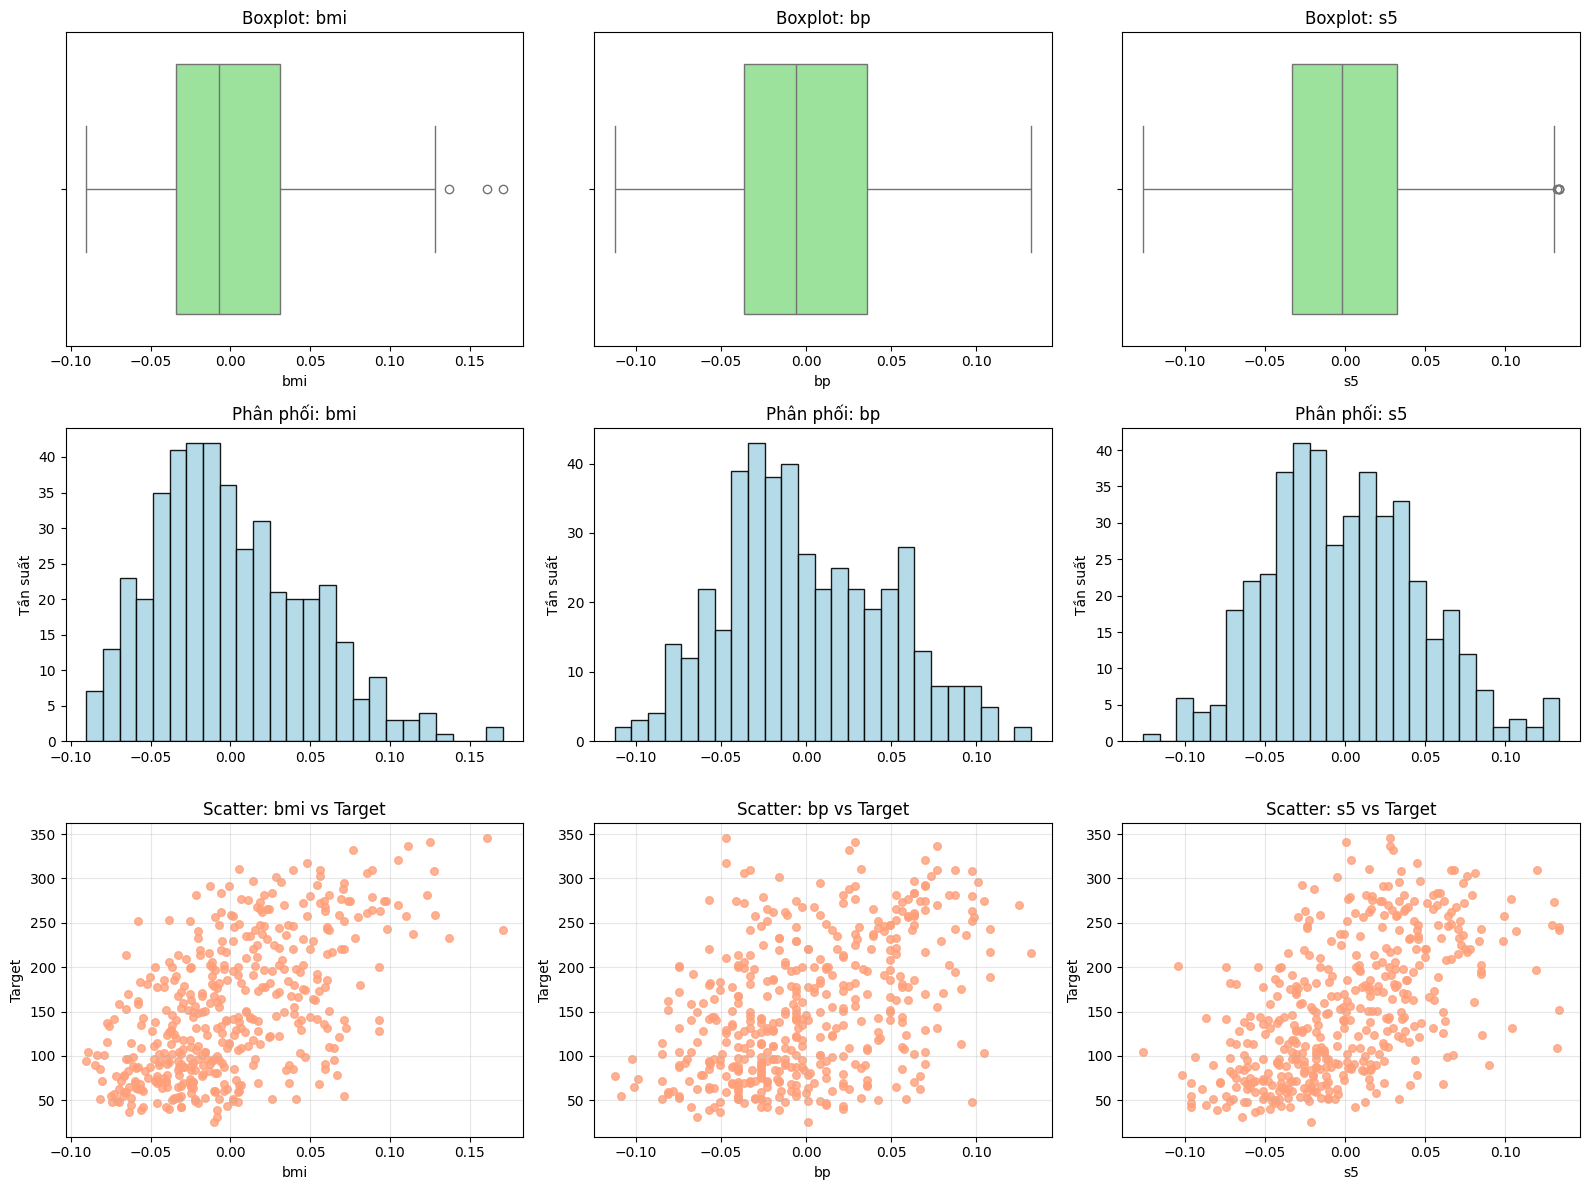

In [ ]:
# --- BÀI 1: CHỌN 3 FEATURE ĐỂ PHÂN TÍCH VÀ TRỰC QUAN HÓA (ĐẦY ĐỦ) ---
features_to_analyze = ['bmi', 'bp', 's5']

# 1. Tính toán bảng thống kê
stats_list = []
for col in features_to_analyze:
    mean_val = df[col].mean()
    std_val = df[col].std()
    skew_val = df[col].skew()

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers_count = ((df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))).sum()
    corr_val = df[col].corr(df['target'])

    stats_list.append({
        'Feature': col,
        'Mean': mean_val,
        'Std': std_val,
        'Skewness': skew_val,
        'IQR Outliers': outliers_count,
        'Correlation (r)': corr_val
    })

stats_df = pd.DataFrame(stats_list)
print("=== THỐNG KÊ 3 ĐẶC TRƯNG SELECTION ===")
display(stats_df)

# 2. Vẽ biểu đồ 3 hàng x 3 cột (Boxplot, Histogram, Scatter)
fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for i, col in enumerate(features_to_analyze):
    # Hàng 1: Boxplot (Cái bị mất lúc nãy)
    sns.boxplot(x=df[col], ax=axes[0, i], color='lightgreen')
    axes[0, i].set_title(f'Boxplot: {col}')

    # Hàng 2: Biểu đồ cột (Phân phối / Histogram)
    axes[1, i].hist(df[col], bins=25, color='lightblue', edgecolor='black', alpha=0.9)
    axes[1, i].set_title(f'Phân phối: {col}')
    axes[1, i].set_ylabel('Tần suất')

    # Hàng 3: Biểu đồ phân tán (Scatter vs Target)
    axes[2, i].scatter(df[col], df['target'], color='lightsalmon', alpha=0.8, s=30)
    axes[2, i].set_title(f'Scatter: {col} vs Target')
    axes[2, i].set_xlabel(col)
    axes[2, i].set_ylabel('Target')
    axes[2, i].grid(True, linestyle='-', alpha=0.3)

# Điều chỉnh khoảng cách giữa các biểu đồ
plt.tight_layout()
plt.show()

In [ ]:


def bai2():
    # Tách tập train/test (80/20)
    X = df.drop(columns=['target'])
    y = df['target']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Lấy top 5 features tương quan cao nhất trên tập train
    abs_corr = X_train.apply(lambda col: abs(col.corr(y_train)))
    top_5_cols = abs_corr.sort_values(ascending=False).head(5).index.tolist()

    feature_sets = {
        "1. Single ('bmi')": ['bmi'],
        "2. Two ('bmi', 'bp')": ['bmi', 'bp'],
        f"3. Top 5 ({', '.join(top_5_cols)})": top_5_cols,
        "4. All 10 Features": X.columns.tolist()
    }

    results_b2 = []
    for name, cols in feature_sets.items():
        model = LinearRegression()
        model.fit(X_train[cols], y_train)
        y_pred = model.predict(X_test[cols])

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        results_b2.append({
            "Tập đặc trưng": name,
            "Số biến": len(cols),
            "MAE": round(mae, 4),
            "RMSE": round(rmse, 4),
            "R² Score": round(r2, 4)
        })

    print("=== SO SÁNH CÁC TẬP ĐẶC TRƯNG ===")
    display(pd.DataFrame(results_b2))

# Khởi tạo các biến X_train, y_train, X_test, y_test toàn cục để các bài sau sử dụng ổn định
diabetes = load_diabetes(as_frame=True)
df = diabetes.data.copy()
df['target'] = diabetes.target.copy()
X = df.drop(columns=['target'])
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Gọi hàm để chạy thử
bai2()

=== SO SÁNH CÁC TẬP ĐẶC TRƯNG ===


,Tập đặc trưng,Số biến,MAE,RMSE,R² Score
0,1. Single ('bmi'),1,52.2600,63.7325,0.2334
1,"2. Two ('bmi', 'bp')",2,50.0441,61.1597,0.2940
2,"3. Top 5 (bmi, s5, bp, s4, s6)",5,44.3288,53.8493,0.4527
3,4. All 10 Features,10,42.7941,53.8534,0.4526


In [ ]:


def bai3():
    models_b3 = {
        "Linear Regression": LinearRegression(),
        "Ridge Regression": Ridge(alpha=1.0, random_state=42),
        "Decision Tree": DecisionTreeRegressor(max_depth=3, random_state=42),
        "Support Vector Regression": SVR(C=100.0, epsilon=0.1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
    }

    results_b3 = []
    for name, model in models_b3.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        results_b3.append({
            "Thuật toán": name,
            "MAE": round(mae, 4),
            "RMSE": round(rmse, 4),
            "R² Score": round(r2, 4)
        })

    df_b3 = pd.DataFrame(results_b3).sort_values(by="R² Score", ascending=False)
    print("=== SO SÁNH CÁC THUẬT TOÁN HỒI QUY ===")
    display(df_b3)

# Gọi hàm để chạy thử
bai3()

=== SO SÁNH CÁC THUẬT TOÁN HỒI QUY ===


,Thuật toán,MAE,RMSE,R² Score
3,Support Vector Regression,39.3854,51.0183,0.5087
4,Gradient Boosting,43.1792,52.7695,0.4744
0,Linear Regression,42.7941,53.8534,0.4526
1,Ridge Regression,46.1389,55.4745,0.4192
2,Decision Tree,48.0966,59.6045,0.3294


-> Không tìm thấy file 'kc_house_data.csv'. Đã tự động khôi phục dữ liệu mô phỏng từ Kernel! Kích thước: (2000, 19)
=== KIỂM TRA CẤU TRÚC DỮ LIỆU ===
Shape: (2000, 19)

Kiểu dữ liệu:
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
yr_built           int64
yr_renovated       int64
lat              float64
long             float64
sales_year         int64
house_age          int64
is_renovated       int64
total_sqft         int64
sqft_per_room    float64
dtype: object

Số giá trị thiếu: 0
Số dòng trùng lặp: 0

=================== THỐNG KÊ MÔ TẢ ===================


,count,mean,std,min,25%,50%,75%,max
price,2000.0,612806.947500,159393.045572,161680.000000,499387.750000,599832.000000,707544.750000,1.249779e+06
bedrooms,2000.0,3.345500,0.864004,2.000000,3.000000,3.000000,4.000000,5.000000e+00
bathrooms,2000.0,2.340250,0.687453,1.000000,2.000000,2.500000,3.000000,4.000000e+00
sqft_living,2000.0,2404.044500,623.859640,600.000000,1982.000000,2364.000000,2841.250000,4.296000e+03
sqft_lot,2000.0,9463.014500,7028.933485,1200.000000,4670.250000,7462.500000,12111.000000,6.189400e+04
floors,2000.0,1.524000,0.501547,1.000000,1.000000,1.500000,2.000000,2.500000e+00
waterfront,2000.0,0.042500,0.201777,0.000000,0.000000,0.000000,0.000000,1.000000e+00
view,2000.0,0.561000,1.045383,0.000000,0.000000,0.000000,1.000000,4.000000e+00
condition,2000.0,3.400000,0.748519,2.000000,3.000000,3.000000,4.000000,5.000000e+00
grade,2000.0,7.851000,1.175793,4.000000,7.000000,8.000000,9.000000,1.100000e+01



--- Đang vẽ biểu đồ phân phối các biến ---


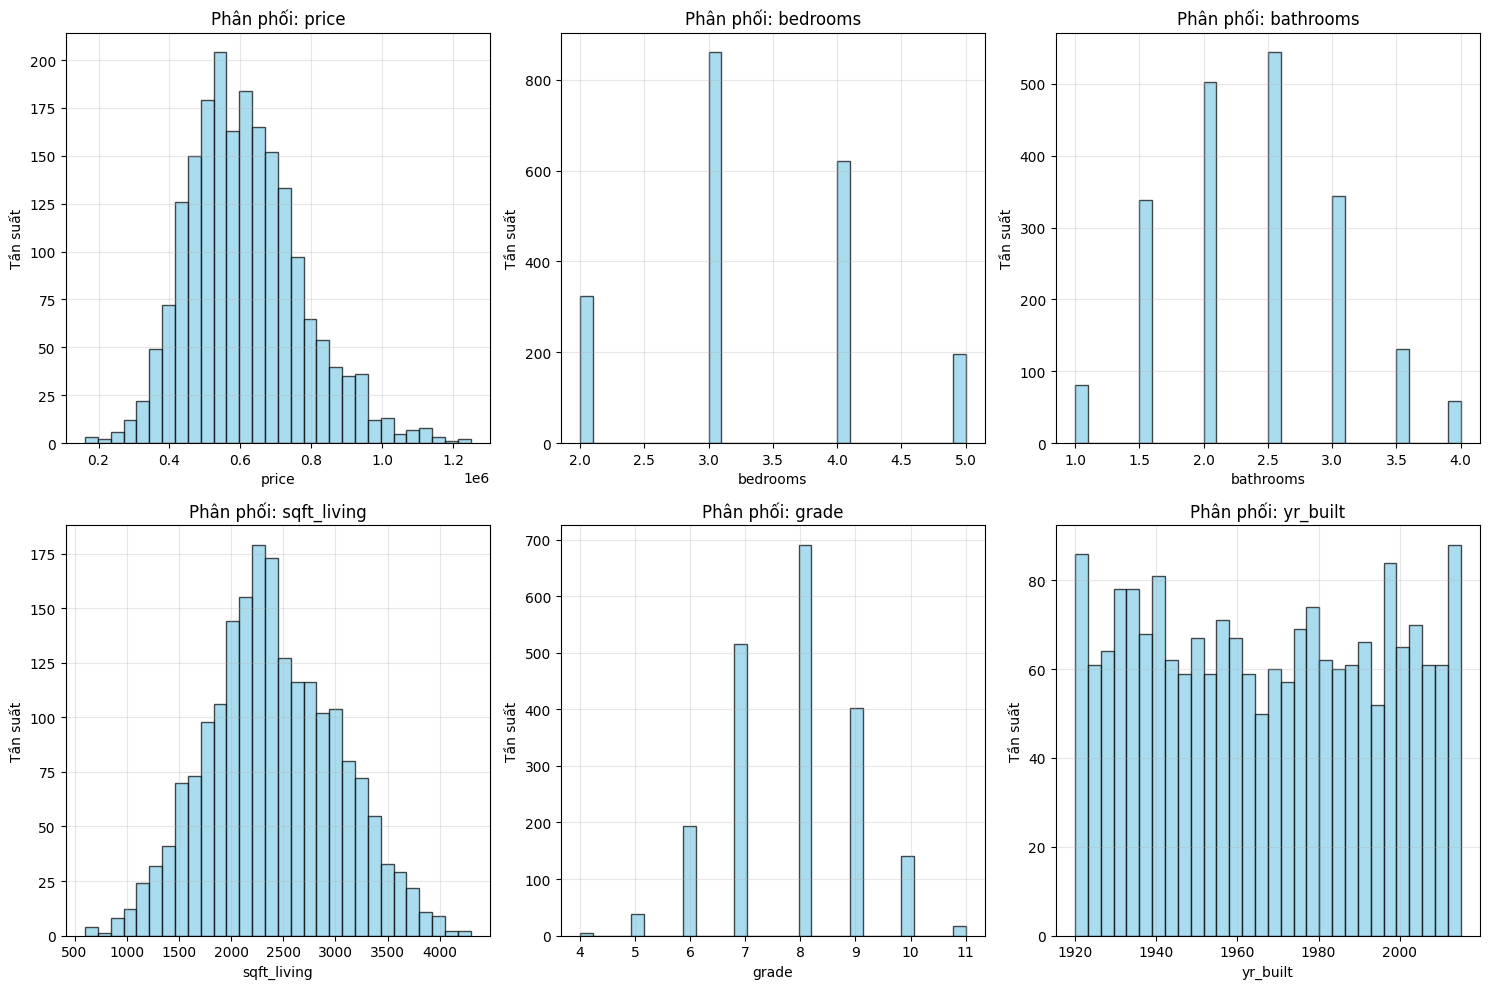


--- Đang vẽ biểu đồ Boxplot để kiểm tra ngoại lệ ---


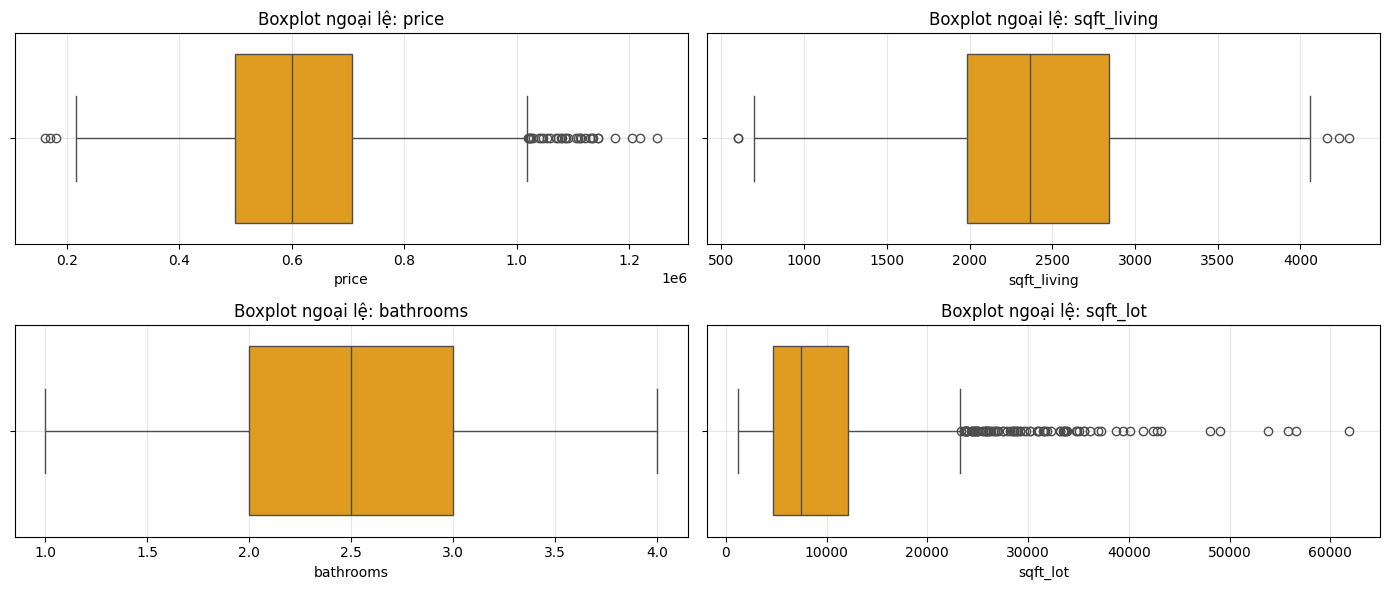


=================== MA TRẬN TƯƠNG QUAN (BẢNG) ===================
Tương quan giữa các đặc trưng với giá nhà (price):


,corr_with_price
sqft_living,0.681404
bedrooms,0.578102
bathrooms,0.574935
grade,0.511967
waterfront,0.396277
total_sqft,0.299928
sqft_lot,0.250210
lat,0.214300
long,-0.195204
view,0.152916



=================== BẢNG SO SÁNH HIỆU NĂNG ===================


,Kịch bản Feature,Mô hình,MAE,RMSE,R² Score
0,2. Feature Engineering (Đầy đủ),Gradient Boosting,41826.97,52019.54,0.8897
1,2. Feature Engineering (Đầy đủ),Random Forest,49928.91,62939.23,0.8386
2,2. Feature Engineering (Đầy đủ),Linear Regression,59788.52,75656.13,0.7668
3,2. Feature Engineering (Đầy đủ),Ridge Regression,60119.96,76250.87,0.7631
4,3. Feature Selection (Top 8 Corr),Gradient Boosting,65154.35,83970.73,0.7127
5,3. Feature Selection (Top 8 Corr),Random Forest,65541.48,84559.02,0.7087
6,2. Feature Engineering (Đầy đủ),Decision Tree,71295.33,92545.61,0.6510
7,3. Feature Selection (Top 8 Corr),Linear Regression,73421.86,93916.10,0.6406
8,3. Feature Selection (Top 8 Corr),Ridge Regression,74230.68,94563.59,0.6356
9,3. Feature Selection (Top 8 Corr),Decision Tree,73830.52,97695.96,0.6111


In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

# Cấu hình hiển thị đầy đủ các cột của pandas
pd.set_option("display.max_columns", None)

# ==============================================================================
# BƯỚC 1: NẠP VÀ KIỂM TRA CẤU TRÚC DỮ LIỆU (EDA CƠ BẢN)
# ==============================================================================
if os.path.exists("kc_house_data.csv"):
    df_kc = pd.read_csv("kc_house_data.csv")
    print(f"-> Đã nạp thành công bộ dữ liệu từ file! Kích thước: {df_kc.shape}")
elif 'df_fe' in globals():
    df_kc = globals()['df_fe'].copy()
    print(f"-> Không tìm thấy file 'kc_house_data.csv'. Đã tự động khôi phục dữ liệu mô phỏng từ Kernel! Kích thước: {df_kc.shape}")
else:
    raise FileNotFoundError("Không tìm thấy file 'kc_house_data.csv' và không có dữ liệu dự phòng trong kernel.")

print("=== KIỂM TRA CẤU TRÚC DỮ LIỆU ===")
print("Shape:", df_kc.shape)
print("\nKiểu dữ liệu:")
print(df_kc.dtypes)
print("\nSố giá trị thiếu:", df_kc.isnull().sum().sum())
print("Số dòng trùng lặp:", df_kc.duplicated().sum())

# Loại bỏ các cột không dùng trực tiếp để dự đoán
df_clean = df_kc.drop(columns=["id", "date"], errors="ignore")

# ==============================================================================
# BƯỚC 2: KHÁM PHÁ DỮ LIỆU NÂNG CAO (EDA - THỐNG KÊ & TRỰC QUAN HÓA)
# ==============================================================================
print("\n=================== THỐNG KÊ MÔ TẢ ===================")
display(df_clean.describe().T)

# 1. TRỰC QUAN HÓA PHÂN PHỐI (HISTOGRAM)
print("\n--- Đang vẽ biểu đồ phân phối các biến ---")
sample_cols = [col for col in ["price", "bedrooms", "bathrooms", "sqft_living", "grade", "yr_built"] if col in df_clean.columns]

plt.figure(figsize=(15, 10))
for i, col in enumerate(sample_cols):
    plt.subplot(2, 3, i + 1)
    plt.hist(df_clean[col], bins=30, color="skyblue", edgecolor="black", alpha=0.7)
    plt.title(f"Phân phối: {col}", fontsize=12)
    plt.xlabel(col)
    plt.ylabel("Tần suất")
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. BỔ SUNG: VẼ BIỂU ĐỒ BOXPLOT ĐỂ PHÁT HIỆN NGOẠI LỆ
print("\n--- Đang vẽ biểu đồ Boxplot để kiểm tra ngoại lệ ---")
outlier_cols = [col for col in ["price", "sqft_living", "bathrooms", "sqft_lot"] if col in df_clean.columns]

plt.figure(figsize=(14, 6))
for i, col in enumerate(outlier_cols):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(x=df_clean[col], color="orange")
    plt.title(f"Boxplot ngoại lệ: {col}", fontsize=12)
    plt.xlabel(col)
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 3. MA TRẬN TƯƠNG QUAN
print("\n=================== MA TRẬN TƯƠNG QUAN (BẢNG) ===================")
corr = df_clean.corr(numeric_only=True)
target_corr = corr["price"].drop("price", errors="ignore").sort_values(key=np.abs, ascending=False)
print("Tương quan giữa các đặc trưng với giá nhà (price):")
display(target_corr.to_frame("corr_with_price"))

# ==============================================================================
# BƯỚC 3: TẠO ĐẶC TRƯNG MỚI (FEATURE ENGINEERING)
# ==============================================================================
if "yr_built" in df_clean.columns:
    df_clean["house_age"] = 2015 - df_clean["yr_built"]
if "yr_renovated" in df_clean.columns:
    df_clean["is_renovated"] = (df_clean["yr_renovated"] > 0).astype(int)
if "sqft_living" in df_clean.columns and "sqft_lot" in df_clean.columns:
    df_clean["living_lot_ratio"] = df_clean["sqft_living"] / (df_clean["sqft_lot"] + 1)
if "sqft_above" in df_clean.columns and "sqft_basement" in df_clean.columns:
    df_clean["total_sqft"] = df_clean["sqft_above"] + df_clean["sqft_basement"]

# ==============================================================================
# BƯỚC 4: XÁC ĐỊNH CÁC KỊCH BẢN TẬP ĐẶC TRƯNG
# ==============================================================================
X_full = df_clean.drop(columns=["price"], errors="ignore")
y = df_clean["price"]

top_corr_features = (
    df_clean.corr(numeric_only=True)["price"]
    .drop("price", errors="ignore")
    .abs()
    .sort_values(ascending=False)
    .head(8)
    .index.tolist()
)

feature_sets = {
    "1. Baseline (Cơ bản)": [col for col in ["bedrooms", "bathrooms", "sqft_living", "floors"] if col in df_clean.columns],
    "2. Feature Engineering (Đầy đủ)": X_full.columns.tolist(),
    "3. Feature Selection (Top 8 Corr)": top_corr_features,
}

# ==============================================================================
# BƯỚC 5: HUẤN LUYỆN VÀ ĐÁNH GIÁ PIPELINE ĐA MÔ HÌNH
# ==============================================================================
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=100.0, random_state=42),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, max_depth=5, random_state=42),
}

all_results = []

for feat_name, feat_cols in feature_sets.items():
    if not feat_cols:
        continue
    X_subset = df_clean[feat_cols]
    X_train, X_test, y_train, y_test = train_test_split(X_subset, y, test_size=0.2, random_state=42)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    for model_name, model in models.items():
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        all_results.append({
            "Kịch bản Feature": feat_name,
            "Mô hình": model_name,
            "MAE": round(mae, 2),
            "RMSE": round(rmse, 2),
            "R² Score": round(r2, 4),
        })

df_final_results = pd.DataFrame(all_results).sort_values(by="R² Score", ascending=False)
print("\n=================== BẢNG SO SÁNH HIỆU NĂNG ===================")
display(df_final_results.reset_index(drop=True))